/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/Simulated Genomic Binary-Class/Heart disease prediction/train.csv
/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/Simulated Genomic Binary-Class/Heart disease prediction/test.csv

(239, 14)
(60, 13)

the number of missing values in the DEATH_EVENT column in the training data is False
the percentage of males who survived are 0.673202614379085

(239, 14)
(239,)
False
DEATH_EVENT
0    162
1     77
Name: count, dtype: int64

['Adaboost_df', 'Adaboost_1', 'Adaboost_2', 'RF_df', 'RF_1', 'RF_2', 'RF_3', 'RF_4', 'XGB_df', 'XGB_1', 'XGB_2', 'XGB_3', 'XGB_4']
Adaboost_df:0.771
Adaboost_1:0.771
Adaboost_2:0.812
RF_df:0.833
RF_1:0.833
RF_2:0.833
RF_3:0.833
RF_4:0.833
XGB_df:0.812
XGB_1:0.833
XGB_2:0.812
XGB_3:0.854
XGB_4:0.854


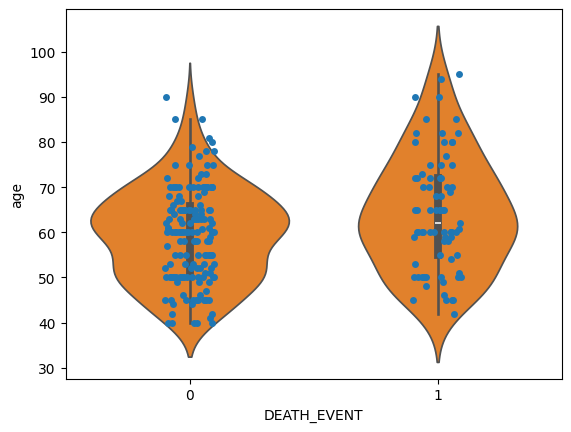

In [41]:

#this is another heart disease prediction, different from the predicting heart disease one I did earlier
import os
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


#get the data directory
hd_train_path = os.path.abspath ('Simulated Genomic Binary-Class/Heart disease prediction/train.csv')
print (hd_train_path)
hd_test_path = os.path.abspath ('Simulated Genomic Binary-Class/Heart disease prediction/test.csv')
print (hd_test_path)
print ()
hd_train_data = pd.read_csv ('/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/train.csv')
print (hd_train_data.shape)
hd_test_data = pd.read_csv ('/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/test.csv')
hd_test_data.head()
print (hd_test_data.shape)
print ()

print (f'the number of missing values in the DEATH_EVENT column in the training data is {hd_train_data.DEATH_EVENT.isnull().values.any()}')

#do some sns visualizations
ax=sns.stripplot (x='DEATH_EVENT', y='age', data=hd_train_data, jitter=True, edgecolor='red')
ax=sns.violinplot(x='DEATH_EVENT', y='age', data=hd_train_data)

male = hd_train_data.loc[hd_train_data.sex==1, 'DEATH_EVENT'] 
percent_male = (male==0).mean()
print (f'the percentage of males who survived are {percent_male}')
print ()

#get the features and target variables 
x = hd_train_data.copy()
print (x.shape)
x.head()
y = x.pop('DEATH_EVENT')
print (y.shape)

print (y.isnull().values.any())
print (y.value_counts())

#do the train, validation split 
x_t, x_v, y_t, y_v = train_test_split (x, y, train_size=0.8, random_state=17, stratify=y)

#models to compare
models = {
     'Adaboost_df': AdaBoostClassifier (random_state=17),
    'Adaboost_1': AdaBoostClassifier (n_estimators=100, random_state=17),
    'Adaboost_2': AdaBoostClassifier (n_estimators=100, learning_rate=0.2, random_state=17),
    'RF_df': RandomForestClassifier (random_state=17),
    'RF_1': RandomForestClassifier (n_estimators=250, random_state=17),
    'RF_2': RandomForestClassifier (n_estimators=250, max_depth=9, random_state=17),
    'RF_3': RandomForestClassifier (n_estimators=250, max_depth=9, min_samples_leaf=5, random_state=17),
    'RF_4': RandomForestClassifier (n_estimators=250, max_depth=None, min_samples_leaf=5, min_samples_split=15, random_state=17),
    'XGB_df': XGBClassifier (random_state=17),
    'XGB_1': XGBClassifier (n_estimators=300, random_state=17),
    'XGB_2': XGBClassifier (n_estimators=300, max_depth=9, random_state=17),
    'XGB_3': XGBClassifier (n_estimators=300, max_depth=9, min_child_weight=5, random_state=17),
    'XGB_4': XGBClassifier (n_estimators=300, max_depth=None, min_child_weight=5, random_state=17),
}

print()
print (list(models.keys()))

#define the scoring function for the models
def model_score (model, x_t, x_v, y_t, y_v):
    model.fit(x_t, y_t)
    pred = model.predict (x_v)
    accu_score = accuracy_score (y_v, pred)
    return accu_score

results = {}

for name, model in models.items():
    accuracy = model_score (model, x_t, x_v, y_t, y_v)
    results [name] = accuracy
    print (f'{name}:{accuracy:.3f}')

#this took less than a minute, less than 30 seconds, probable because the list of features is few

In [48]:
best_model_name = max(results, key=results.get)
print (best_model_name)

best_model = models[best_model_name]
print (best_model)

#retrain on the whole training dataset 
best_model.fit (x,y)

#predict on test data
test_pred = best_model.predict(hd_test_data)

#view preds
print (test_pred[:10])

submission = pd.DataFrame ({
    'id':hd_test_data['id'],
    'DEATH_EVENT':test_pred})

submission.to_csv ('hd_prediction.csv', index=False)

print ('another heart prediction done')

XGB_3
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=9,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)
[0 0 1 0 0 0 0 0 0 0]
another heart prediction done


                     Feature  Importance
8           serum_creatinine    0.186312
5          ejection_fraction    0.173905
0                         id    0.166503
6        high_blood_pressure    0.097482
7                  platelets    0.076279
10                       sex    0.072384
3   creatinine_phosphokinase    0.060905
9               serum_sodium    0.059865
1                        age    0.054382
2                    anaemia    0.030095
11                   smoking    0.021888
4                   diabetes    0.000000
12                      time    0.000000


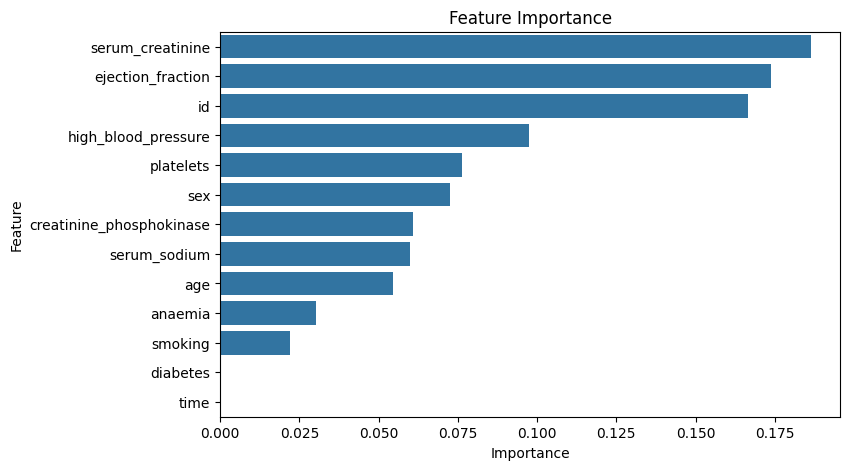

In [54]:
import matplotlib.pyplot as plt

importance = pd.DataFrame ({
    'Feature': x.columns,
    'Importance' : best_model.feature_importances_})

importance = importance.sort_values (by='Importance', ascending=False)

print (importance)

plt.figure (figsize=(8,5))
sns.barplot(x='Importance', y = 'Feature', data = importance)
plt.title ('Feature Importance')
plt.show()

/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/Simulated Genomic Binary-Class/Heart disease prediction/train.csv
/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/Simulated Genomic Binary-Class/Heart disease prediction/test.csv

(239, 14)
(60, 13)

The number of missing values in the training data is False
The number of missing values in the test data is False
The shape of the x training data is (239, 12)
The shape of the target data is (239,)
The shape of x training data after removing the target column is(239, 12)
0    274
1    149
2    120
3    226
4    125
Name: id, dtype: int64
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Fitting 5 folds for each of 10 candidates, totalling 50 fits


,Accuracy,Balanced_Accuracy,Macro_f1,Macro-Recall,ROC AUC
XGBoost,0.900000,0.879121,0.887500,0.879121,0.926740
AdaBoost,0.866667,0.831502,0.845956,0.831502,0.921245
RandomForest,0.866667,0.831502,0.845956,0.831502,0.910867


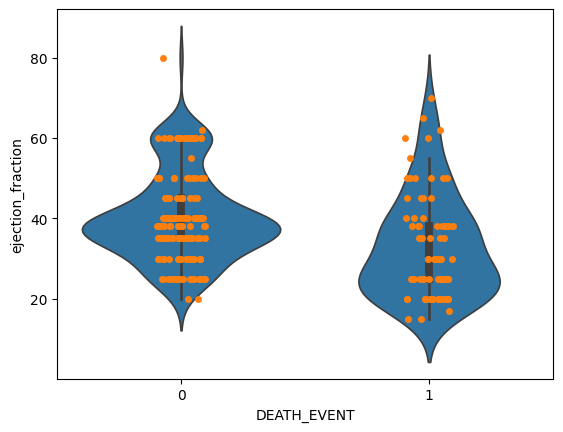

In [2]:

#evaluating different hyperparameters to get the best model; using hyperparameter sweep
#using RandomizedSearchCV to do the cross validation

import os
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


#get the data directory
hd_train_path = os.path.abspath ('Simulated Genomic Binary-Class/Heart disease prediction/train.csv')
print (hd_train_path)
hd_test_path = os.path.abspath ('Simulated Genomic Binary-Class/Heart disease prediction/test.csv')
print (hd_test_path)
print ()
hd_train_data = pd.read_csv ('/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/train.csv')
print (hd_train_data.shape)
hd_test_data = pd.read_csv ('/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/test.csv')
hd_test_data.head()
print (hd_test_data.shape)
print ()

print (f'The number of missing values in the training data is {hd_train_data.isnull().values.any()}')
print (f'The number of missing values in the test data is {hd_test_data.isnull().values.any()}')

#ax = sns.stripplot (x='sex', y='DEATH_EVENT', jitter=True, data=hd_train_data)
#ax = sns.violinplot (x= 'sex', y='DEATH_EVENT', data=hd_train_data)
ax = sns.violinplot (x= 'DEATH_EVENT', y ='ejection_fraction', data=hd_train_data) 
ax = sns.stripplot (x='DEATH_EVENT', y='ejection_fraction', data=hd_train_data, jitter=True)

hd_train_data['DEATH_EVENT'].value_counts() #check any class imbalances to determine which metrices to use to determine model efficiency

#get the features and target
x = hd_train_data.drop (columns=['id', 'DEATH_EVENT']) #don't want to use id column as part of the training data, only 'useful' features
print (f'The shape of the x training data is {x.shape}')
y = hd_train_data['DEATH_EVENT']
print (f'The shape of the target data is {y.shape}')
print (f'The shape of x training data after removing the target column is{x.shape}')

test_ids=hd_test_data.pop ('id') #dropping the id column because we don't want the values in the id column to be used as features
print (test_ids.head())
x.describe()


#do the train test split
x_t, x_v, y_t, y_v = train_test_split (x, y, random_state=17)


#define parameters for adaboost, randomforest & xgboost
ada_params = {
    'n_estimators': [5, 25, 50, 100],
    'learning_rate': [0.01, 0.02, 0.1, 0.3]}

rf_params = {
    'n_estimators': [5, 25, 50, 100],
    'max_depth': [None, 5, 9, 15],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1,3,5]}

xgb_params = {
    'n_estimators': [5, 25, 50, 100],
    'max_depth': [3, 6, 9],
    'learning_rate': [0.01, 0.02, 0.1, 0.2],
    'min_child_weight': [1,3,5]}

#try randomizedsearchcv
ada_search = RandomizedSearchCV (
    AdaBoostClassifier (random_state=17),
    ada_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    random_state=17)
ada_search.fit (x_t, y_t)

rf_search = RandomizedSearchCV(
    RandomForestClassifier (random_state=17, n_jobs=1),
    rf_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    random_state=17)
rf_search.fit(x_t, y_t)

xgb_search = RandomizedSearchCV (
    XGBClassifier (random_state=17, n_jobs=1),
    xgb_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    random_state=17)
xgb_search.fit (x_t, y_t)

#get the best models
best_models = {
    'AdaBoost': ada_search.best_estimator_,
    'RandomForest': rf_search.best_estimator_,
    'XGBoost': xgb_search.best_estimator_}


#define the function that evaluates the models using the metrics after a hyperparameter sweep
def eval_model (model, x_v, y_v):
    preds = model.predict (x_v)
    probs = model.predict_proba (x_v)[:,1]
    return {
      'Accuracy': accuracy_score(y_v, preds),
      'Balanced_Accuracy': balanced_accuracy_score(y_v, preds),
      'Macro_f1': f1_score (y_v, preds, average='macro'),
      'Macro-Recall': recall_score (y_v, preds, average='macro'),
      'ROC AUC': roc_auc_score(y_v, probs)}

#compare the best versions
results ={}

for name, model in best_models.items():
    results[name] = eval_model(model, x_v, y_v)

results_df = pd.DataFrame(results).T

results_df.sort_values (
    by = 'Macro_f1',
    ascending=False)

#this took less than 2 seconds

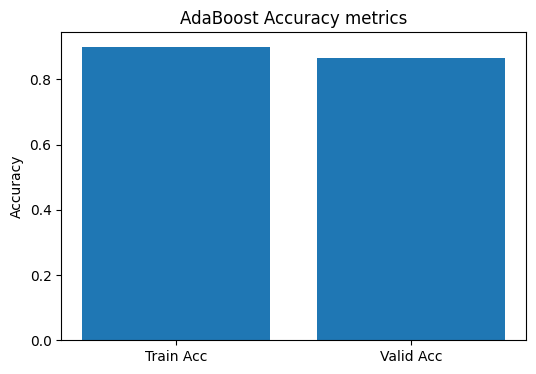

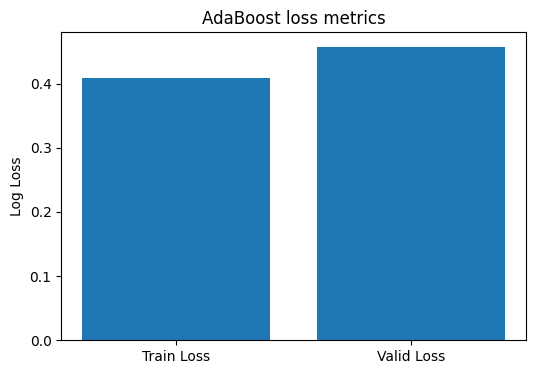


AdaBoost
Train Accuracy: 0.8994
Valid Accuracy: 0.8667
Accuracy Gap: 0.0328
Train Loss: 0.4091
Valid Loss: 0.4571

RandomForest
Train Accuracy: 0.9218
Valid Accuracy: 0.8667
Accuracy Gap: 0.0551
Train Loss: 0.2500
Valid Loss: 0.3735

XGBoost
Train Accuracy: 0.9330
Valid Accuracy: 0.9000
Accuracy Gap: 0.0330
Train Loss: 0.2008
Valid Loss: 0.3405

AdaBoost
macro f1 training score: 0.8794
macro f1 validation score: 0.8460
macro f1 score gap: 0.03342369960797065

RandomForest
macro f1 training score: 0.9072
macro f1 validation score: 0.8460
macro f1 score gap: 0.06122883088479991

XGBoost
macro f1 training score: 0.9235
macro f1 validation score: 0.8875
macro f1 score gap: 0.035982473639213586


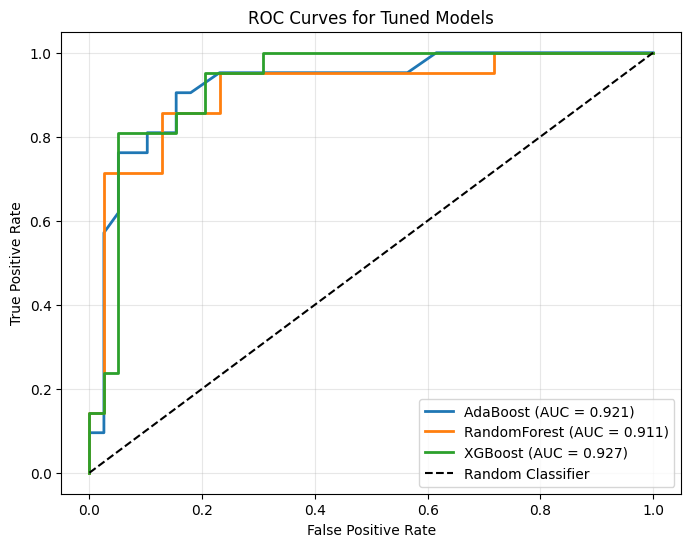

In [3]:
from sklearn.metrics import accuracy_score, log_loss, roc_curve, auc
import matplotlib.pyplot as plt

ada_model = ada_search.best_estimator_


#training metrics
train_pred = ada_model.predict(x_t)
train_prob = ada_model.predict_proba (x_t)

train_acc = accuracy_score (y_t, train_pred)
train_loss = log_loss (y_t, train_prob)

#validation metrics
valid_pred = ada_model.predict (x_v)
valid_prob = ada_model.predict_proba (x_v)

valid_acc = accuracy_score (y_v, valid_pred)
valid_loss = log_loss (y_v, valid_prob)

#accuracy plot
plt.figure (figsize=(6,4))
plt.bar (['Train Acc', 'Valid Acc'],
         [train_acc, valid_acc])
plt.ylabel('Accuracy')
plt.title ('AdaBoost Accuracy metrics')
plt.show()

#loss plot 
plt.figure(figsize=(6,4))
plt.bar (['Train Loss', 'Valid Loss'],
         [train_loss, valid_loss])
plt.ylabel('Log Loss')
plt.title ('AdaBoost loss metrics')
plt.show()


from sklearn.metrics import accuracy_score, log_loss, f1_score

for name, model in best_models.items():

    train_pred = model.predict(x_t)
    train_prob = model.predict_proba(x_t)

    valid_pred = model.predict(x_v)
    valid_prob = model.predict_proba(x_v)

    train_acc = accuracy_score(y_t, train_pred)
    valid_acc = accuracy_score(y_v, valid_pred)

    train_loss = log_loss(y_t, train_prob)
    valid_loss = log_loss(y_v, valid_prob)

    print(f"\n{name}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Valid Accuracy: {valid_acc:.4f}")
    print(f"Accuracy Gap: {train_acc-valid_acc:.4f}")

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Valid Loss: {valid_loss:.4f}")

for name, model in best_models.items():
    train_pred = model.predict (x_t)
    val_pred = model.predict (x_v)

    f1_train = f1_score(y_t, train_pred, average='macro')
    f1_val = f1_score(y_v, val_pred, average='macro')

    print (f'\n{name}')
    print (f'macro f1 training score: {f1_train:.4f}')
    print (f'macro f1 validation score: {f1_val:.4f}')
    print (f'macro f1 score gap: {f1_train - f1_val}')

plt.figure (figsize=(8,6))
for name, model in best_models.items():
    #probability of positive class 
    probs = model.predict_proba (x_v)[:,1]

    #compute roc curve
    fpr, tpr, thresholds = roc_curve (y_v, probs)

    #compute AUC
    auc_score = roc_auc_score(y_v, probs)
    #roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{name} (AUC = {roc_auc_score(y_v, probs):.3f})')
    #random guessing line
plt.plot (
    [0,1],
    [0,1],
    linestyle='--',
    color='black',
    label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Tuned Models')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

    

In [19]:
best_model_name =  max(results, key =lambda name:results[name]['Macro_f1'])
print (best_model_name)

print(type(best_model_name))
best_model = best_models[best_model_name]
print (type(best_model))

#fit all the training data
best_model.fit (x,y)

#predict on the test data
test_preds = best_model.predict (hd_test_data)

submission = pd.DataFrame ({
    'id': test_ids,
    'DEATH_EVENT': test_preds})
submission.to_csv ('hd_pred.csv', index=False)

print ('Successfully predicted heart disease using a hyperparameter sweep of models')

XGBoost
<class 'str'>
<class 'xgboost.sklearn.XGBClassifier'>
Successfully predicted heart disease using a hyperparameter sweep of models


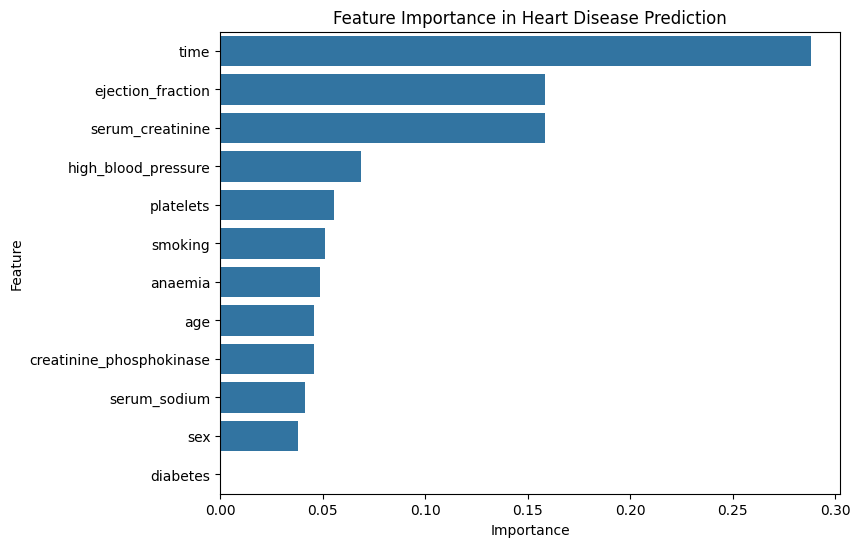

                     Feature  Importance
11                      time    0.288037
4          ejection_fraction    0.158512
7           serum_creatinine    0.158288
5        high_blood_pressure    0.068813
6                  platelets    0.055734
10                   smoking    0.050908
1                    anaemia    0.048875
0                        age    0.045945
2   creatinine_phosphokinase    0.045730
8               serum_sodium    0.041169
9                        sex    0.037990
3                   diabetes    0.000000


In [25]:

importance = pd.DataFrame ({
    'Feature':x.columns,
    'Importance':best_model.feature_importances_})

importance = importance.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(data=importance, x='Importance', y='Feature')
plt.title('Feature Importance in Heart Disease Prediction')
plt.show()
        
print (importance)    
#xgb_search.best_estimator_ to check the parameters

/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/Simulated Genomic Binary-Class/Heart disease prediction/train.csv
/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/Simulated Genomic Binary-Class/Heart disease prediction/test.csv

(239, 14)
(60, 13)

The number of missing values in the training data is False
The number of missing values in the test data is False
The shape of the x training data is (239, 12)
The shape of the target data is (239,)
The shape of x training data after removing the target column is(239, 12)
0    274
1    149
2    120
3    226
4    125
Name: id, dtype: int64
Fitting 5 folds for each of 16 candidates, totalling 80 fits
Fitting 5 folds for each of 192 candidates, totalling 960 fits
Fitting 5 folds for each of 144 candidates, totalling 720 fits


,Accuracy,Balanced_Accuracy,Macro_f1,Macro-Recall,ROC AUC
XGBoost,0.900000,0.879121,0.887500,0.879121,0.926740
AdaBoost,0.866667,0.831502,0.845956,0.831502,0.921245
RandomForest,0.850000,0.807692,0.824162,0.807692,0.914530


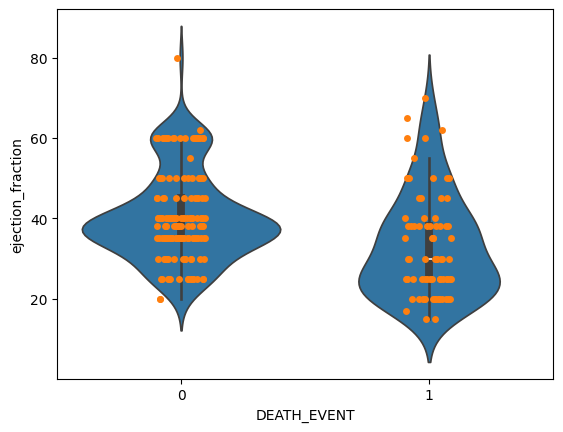

In [22]:

#evaluating different hyperparameters to get the best model; using hyperparameter sweep
#using GridSearchCV to do the cross validation

import os
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, roc_auc_score
import matplotlib.pyplot as plt


#get the data directory
hd_train_path = os.path.abspath ('Simulated Genomic Binary-Class/Heart disease prediction/train.csv')
print (hd_train_path)
hd_test_path = os.path.abspath ('Simulated Genomic Binary-Class/Heart disease prediction/test.csv')
print (hd_test_path)
print ()
hd_train_data = pd.read_csv ('/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/train.csv')
print (hd_train_data.shape)
hd_test_data = pd.read_csv ('/Users/drstevenzeki/Simulated Genomic Binary-Class/Heart disease prediction/test.csv')
hd_test_data.head()
print (hd_test_data.shape)
print ()

print (f'The number of missing values in the training data is {hd_train_data.isnull().values.any()}')
print (f'The number of missing values in the test data is {hd_test_data.isnull().values.any()}')

#ax = sns.stripplot (x='sex', y='DEATH_EVENT', jitter=True, data=hd_train_data)
#ax = sns.violinplot (x= 'sex', y='DEATH_EVENT', data=hd_train_data)
ax = sns.violinplot (x= 'DEATH_EVENT', y ='ejection_fraction', data=hd_train_data) 
ax = sns.stripplot (x='DEATH_EVENT', y='ejection_fraction', data=hd_train_data, jitter=True)

hd_train_data['DEATH_EVENT'].value_counts() #check any class imbalances to determine which metrices to use to determine model efficiency

#get the features and target
x = hd_train_data.drop (columns=['id', 'DEATH_EVENT']) #don't want to use id column as part of the training data, only 'useful' features
print (f'The shape of the x training data is {x.shape}')
y = hd_train_data['DEATH_EVENT']
print (f'The shape of the target data is {y.shape}')
print (f'The shape of x training data after removing the target column is{x.shape}')

test_ids=hd_test_data.pop ('id') #dropping the id column because we don't want the values in the id column to be used as features
print (test_ids.head())
x.describe()


#do the train test split
x_t, x_v, y_t, y_v = train_test_split (x, y, random_state=17)


#define parameters for adaboost, randomforest & xgboost
ada_params = {
    'n_estimators': [5, 25, 50, 100],
    'learning_rate': [0.01, 0.02, 0.1, 0.3]}

rf_params = {
    'n_estimators': [5, 25, 50, 100],
    'max_depth': [None, 5, 9, 15],
    'min_samples_split': [2, 5, 10, 15],
    'min_samples_leaf': [1,3,5]}

xgb_params = {
    'n_estimators': [5, 25, 50, 100],
    'max_depth': [3, 6, 9],
    'learning_rate': [0.01, 0.02, 0.1, 0.2],
    'min_child_weight': [1,3,5]}

#try randomizedsearchcv
ada_search = GridSearchCV (
    AdaBoostClassifier (random_state=17),
    ada_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1)
    #random_state=17
ada_search.fit (x_t, y_t)

rf_search = GridSearchCV(
    RandomForestClassifier (random_state=17, n_jobs=1),
    rf_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1)
    #random_state=17
rf_search.fit(x_t, y_t)

xgb_search = GridSearchCV (
    XGBClassifier (random_state=17, n_jobs=1),
    xgb_params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1)
    #random_state=17)
xgb_search.fit (x_t, y_t)

#get the best models
best_models = {
    'AdaBoost': ada_search.best_estimator_,
    'RandomForest': rf_search.best_estimator_,
    'XGBoost': xgb_search.best_estimator_}


#define the function that evaluates the models using the metrics after a hyperparameter sweep
def eval_model (model, x_v, y_v):
    preds = model.predict (x_v)
    probs = model.predict_proba (x_v)[:,1]
    return {
      'Accuracy': accuracy_score(y_v, preds),
      'Balanced_Accuracy': balanced_accuracy_score(y_v, preds),
      'Macro_f1': f1_score (y_v, preds, average='macro'),
      'Macro-Recall': recall_score (y_v, preds, average='macro'),
      'ROC AUC': roc_auc_score(y_v, probs)}

#compare the best versions
results ={}

for name, model in best_models.items():
    results[name] = eval_model(model, x_v, y_v)

results_df = pd.DataFrame(results).T

results_df.sort_values (
    by = 'Macro_f1',
    ascending=False)


#this took less than 5 seconds